# Themes

One drawing in every built-in theme, a variant computed with `=` expressions, a theme read from TOML and
saved back with its comments, and a theme made the default for a block of code.

Run it as ``python 14_themes.py`` or open ``14_themes.ipynb`` to see each step.

In [1]:
import svgwriter as svg

Elements take a *role* (`as_role("box")`) instead of colors. The document's theme turns each role
into one CSS rule, so the SVG holds a small `<style>` sheet and class names, and stays restylable.
Builder shapes carry roles already: `star` is a `shape`, `arrow` an `arrow.line`, `dot` a `dot`.

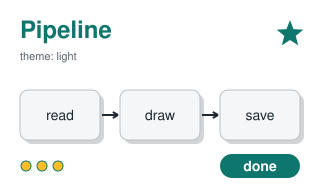

In [2]:
WIDTH, HEIGHT = 320, 190
SHADOW = 4


def card(theme: svg.Theme | str = "light") -> svg.Document:
    """A small diagram drawn only with roles."""
    doc = svg.Document(WIDTH, HEIGHT, theme=theme)
    doc.rect(0, 0, WIDTH, HEIGHT, rx=12).as_role("background")
    doc.text("Pipeline", x=20, y=38).as_role("title")
    doc.text(f"theme: {doc.theme.name}", x=20, y=60).as_role("caption")
    for index, label in enumerate(("read", "draw", "save")):
        x = 20 + index * 100
        doc.rect(x + SHADOW, 90 + SHADOW, 80, 50, rx=8).as_role("shadow")
        doc.rect(x, 90, 80, 50, rx=8).as_role("box")
        doc.text(label, x=x + 40, y=120, text_anchor="middle").as_role("text")
        if index:
            doc += svg.builder.arrow(x - 18, 115, x - 2, 115, head=6)
    for index in range(3):
        doc += svg.builder.dot(26 + index * 16, 166, 5)
    doc.rect(220, 154, 80, 24, rx=12).as_role("shape")
    doc.text("done", x=260, y=171, text_anchor="middle").as_role("label")
    doc += svg.builder.star(290, 34, 14, 6)
    return doc


card()

The same function in other built-in themes: `dark`, `paper`, `print` (serif, ink blue, for papers),
`mono` (black and white only), `noir`, `brutalist`, and the editor palettes `dracula`, `alucard`,
`one-dark` and `one-light`.

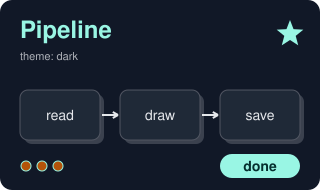

In [3]:
card("dark")

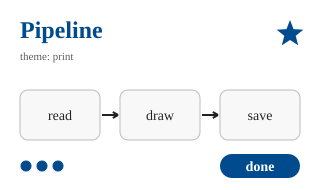

In [4]:
card("print")

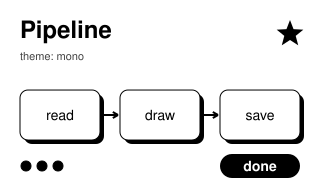

In [5]:
card("mono")

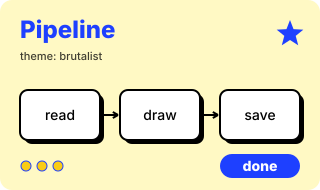

In [6]:
card("brutalist")

Every registered theme side by side: each card is rendered with its own theme and placed as pixels.

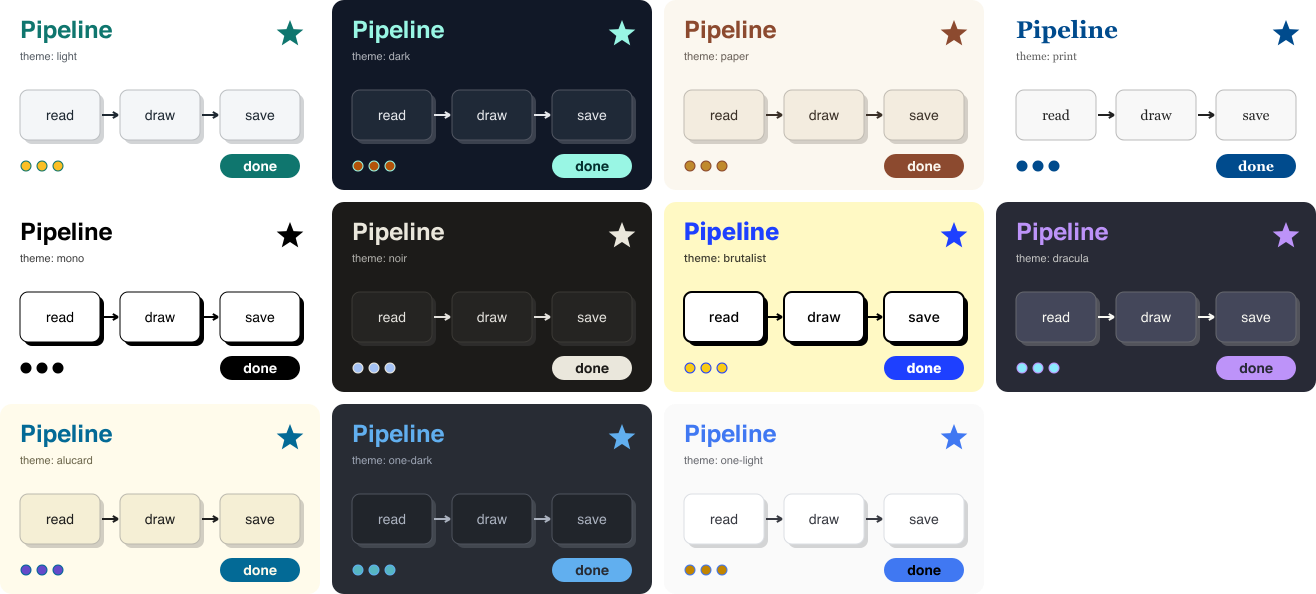

In [7]:
COLUMNS, GAP, SCALE = 4, 12, 2


def sheet(names: list[str] | None = None) -> svg.Document:
    """One card per theme in a grid, in registration order."""
    names = names or svg.THEMES.list()
    rows = -(-len(names) // COLUMNS)
    doc = svg.Document(COLUMNS * (WIDTH + GAP) - GAP, rows * (HEIGHT + GAP) - GAP)
    for index, name in enumerate(names):
        x, y = (index % COLUMNS) * (WIDTH + GAP), (index // COLUMNS) * (HEIGHT + GAP)
        doc += svg.Image(card(name).rasterize(scale=SCALE), x, y, WIDTH, HEIGHT)
    return doc


sheet()

`replace` builds a variant: palette entries, fonts and role properties merge into the base theme.
A value that starts with `=` is an expression, like a spreadsheet formula: derived colors and sizes
follow their sources. Text without `=` is never evaluated, so plain colors, `{palette.name}`
references and CSS such as `"1px solid {palette.border}"` stay as written.

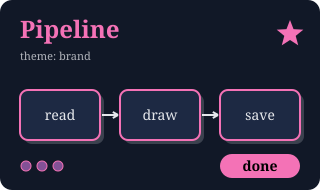

In [8]:
brand = svg.Theme.get("dark").replace(
    name="brand",
    palette={
        "primary": "#f472b6",
        "on_primary": "=readable({palette.primary})",
        "surface": "=lighten({palette.background}, 0.08)",
        "accent": "=mix({palette.primary}, {palette.background}, 0.4, 'oklch')",
    },
    fonts={"family": "Georgia, serif"},
    roles={"box": {"stroke": "{palette.primary}", "stroke-width": "=max(2, {fonts.sizes.text} / 8)"}},
)
card(brand)

Themes are saved and read as TOML, and a file extends a registered theme. A theme read from a file
remembers it: saving a variant edits that text, so comments, layout, references and expressions stay,
and only the edited keys change.

# Night: sky blue on the dark theme
name = "dusk"
extends = "dark"

[palette]
primary = "#f59e0b"   # sky
on_primary = "=readable({palette.primary})"
accent = "{palette.primary}"

[roles.title]
fill = "{palette.primary}"
font-size = "={fonts.sizes.title} * 1.1"



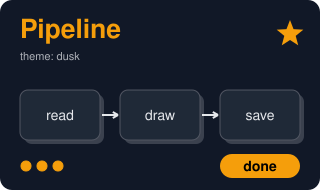

In [9]:
NIGHT = """# Night: sky blue on the dark theme
name = "night"
extends = "dark"

[palette]
primary = "#38bdf8"   # sky
on_primary = "=readable({palette.primary})"
accent = "{palette.primary}"

[roles.title]
fill = "{palette.primary}"
font-size = "={fonts.sizes.title} * 1.1"
"""
night = svg.Theme.from_toml(NIGHT)
dusk = night.replace(name="dusk", palette={"primary": "#f59e0b"})
print(dusk.to_toml())
card(dusk)

`with theme:` makes a theme the default for documents created inside the block.

In [10]:
with svg.Theme.get("paper"):
    default = svg.Document(120, 40)
default.theme.name

'paper'

The themed drawing exports like any other: the renderers resolve the style sheet.

In [11]:
if __name__ == "__main__":
    brand.save("brand.toml")
    for name in svg.THEMES.list():
        card(name).save(f"themes-{name}.svg")
    sheet().save("14_themes.svg")
    card(brand).save("themes-brand.png", scale=2)